Dataset shape: (7950, 9)
    N   P   K  temperature   humidity        ph    rainfall label  soil_type
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice  Clay Loam
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice  Clay Loam
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice  Clay Loam
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice  Clay Loam
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice  Clay Loam
<class 'pandas.DataFrame'>
RangeIndex: 7950 entries, 0 to 7949
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            7950 non-null   int64  
 1   P            7950 non-null   int64  
 2   K            7950 non-null   int64  
 3   temperature  7950 non-null   float64
 4   humidity     7950 non-null   float64
 5   ph           7950 non-null   float64
 6   rainfall     7950 non-null   float64
 7   label        7950 non-null   str   

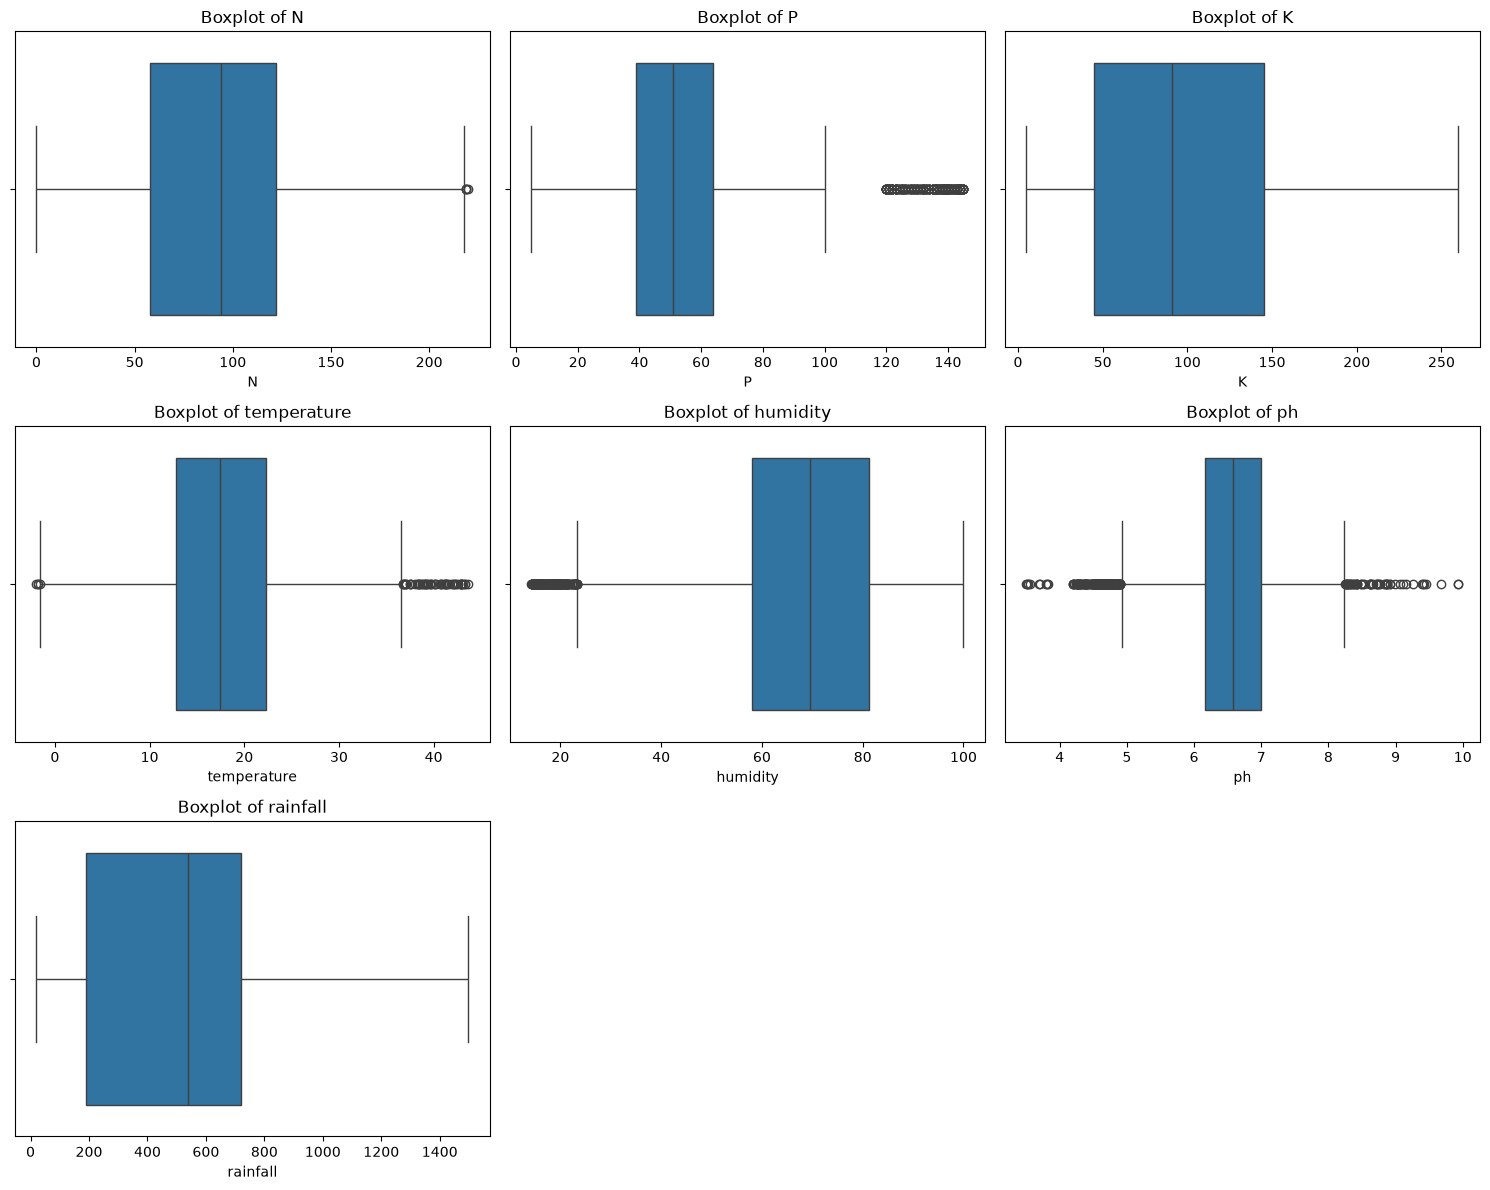

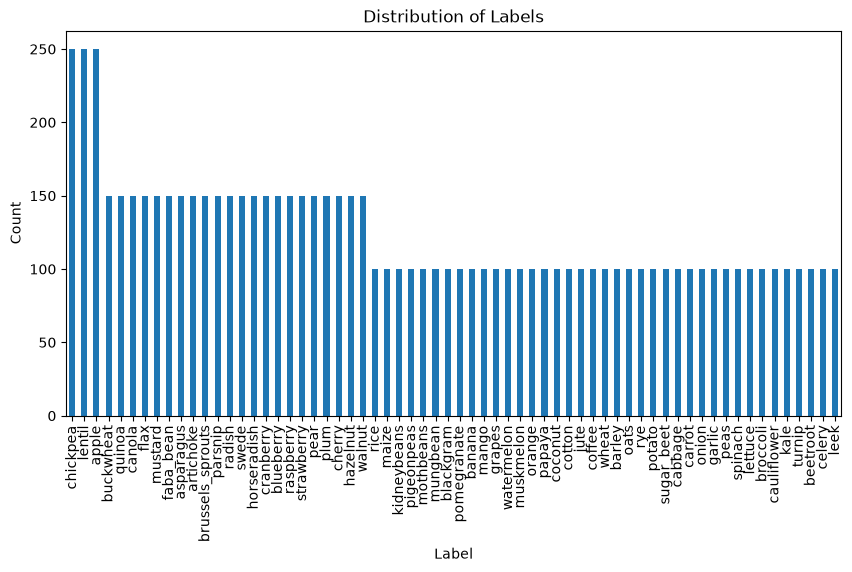


Scaled training data sample:
             N         P         K  temperature  humidity        ph  rainfall  \
1584 -1.370461  3.470820  1.645089     0.635002  1.655021 -0.735330 -1.275475   
938  -1.867206 -1.303415 -0.951107     1.004760  1.603857 -0.390287 -1.302175   
2347  0.206165 -0.447656 -0.917823    -1.111981 -0.349738  1.897917  0.229817   
4259  0.162970  0.137864 -0.518408    -2.456424 -1.275149  0.389139  0.018850   
1329 -0.074604 -1.078215 -0.768042     1.008605  1.291499 -0.686502 -1.484177   

      soil_type  
1584   2.274687  
938   -0.111034  
2347   1.320399  
4259  -0.588178  
1329   1.320399  


In [3]:
import math
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1) Load data
# --------------------------------------------------
df = pd.read_csv("Crop_Recommendation_data.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# --------------------------------------------------
# 2) EDA
# --------------------------------------------------
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Outlier detection
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

if ((df[numeric_cols] < lower_bound) | (df[numeric_cols] > upper_bound)).any().any():
    print("\nOutliers detected in the dataset.")

# Boxplots
num_features = len(numeric_cols)
num_cols = 3
num_rows = math.ceil(num_features / num_cols)

plt.figure(figsize=(15, 4 * num_rows))
for i, feature in enumerate(numeric_cols, start=1):
    plt.subplot(num_rows, num_cols, i)
    sns.boxplot(x=df[feature])
    plt.title(f"Boxplot of {feature}")
    plt.xlabel(feature)

plt.tight_layout()
plt.show()

# Target distribution
df["label"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.xlabel("Label")
plt.ylabel("Count")
plt.title("Distribution of Labels")
plt.show()

# --------------------------------------------------
# 3) Prepare features and target
# --------------------------------------------------
X = df.drop(columns=["label"])
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Encode categorical feature
soil_encoder = LabelEncoder()
X_train["soil_type"] = soil_encoder.fit_transform(X_train["soil_type"])
X_test["soil_type"] = soil_encoder.transform(X_test["soil_type"])

# Encode target labels
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

# --------------------------------------------------
# 4) Scale features
# --------------------------------------------------
scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\nScaled training data sample:")
print(X_train.head())



In [8]:
# --------------------------------------------------
# 5) Build model dictionary
# --------------------------------------------------
try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False

models = {
    
    "RandomForestClassifier": RandomForestClassifier(n_estimators=100, random_state=42),
      
   
}


# --------------------------------------------------
# 6) Train and evaluate models
# --------------------------------------------------
results = []

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    results.append({
        "model": model_name,
        "accuracy": accuracy,
        "report": report,
        "confusion_matrix": cm
    })

    print(f"{model_name} Accuracy: {accuracy:.4f}")
    print("Classification Report:\n", report)
    print("Confusion Matrix:\n", cm)

# --------------------------------------------------
# 7) Best model summary
# --------------------------------------------------
sorted_results = sorted(results, key=lambda x: x["accuracy"], reverse=True)
print("\nBest models by accuracy:")
for item in sorted_results:
    print(f"{item['model']}: {item['accuracy']:.4f}")

best_model_name = sorted_results[0]["model"]
best_model = models[best_model_name]

joblib.dump(best_model, "RF_crop_model.pkl")
print(f"\nBest model saved as: RF_crop_model.pkl")


Training RandomForestClassifier...
RandomForestClassifier Accuracy: 0.7635
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.64      0.69        75
           1       0.81      0.84      0.83        45
           2       0.90      0.78      0.83        45
           3       1.00      1.00      1.00        30
           4       0.85      0.73      0.79        30
           5       0.45      0.47      0.46        30
           6       1.00      1.00      1.00        30
           7       0.79      0.82      0.80        45
           8       0.33      0.37      0.35        30
           9       0.76      0.69      0.72        45
          10       0.88      0.96      0.91        45
          11       0.58      0.60      0.59        30
          12       0.89      0.87      0.88        45
          13       0.70      0.53      0.60        30
          14       0.67      0.60      0.63        30
          15       1.00      0.97  